In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/daily_usage_messy.csv", dtype=str, keep_default_na=False)
raw = df.copy()
print(df.shape)

(265311, 19)


In [2]:
print(list(df.columns))
df.sample(10, random_state=1)

['record_id', 'user_id', 'date', 'day_index', 'day_of_week', 'is_weekend', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'physical_activity_minutes', 'stress_score', 'mood_score', 'is_anomaly', 'anomaly_type', 'stress_level']


,record_id,user_id,date,day_index,day_of_week,is_weekend,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,physical_activity_minutes,stress_score,mood_score,is_anomaly,anomaly_type,stress_level
159642,R0138694,U04624,"Sep 04, 2026",4,Friday,0,3.33,0.36,0.92,1.84,8.85,86,171,82,5,5.6,0,none,Medium
149137,R0103836,U03462,2026-09-06,6,Sunday,1,10.48,2.67,2.8,1.14,5,239,51,47,3.4,6.6,0,none,Low
97701,R0077508,U02584,18 Sep 2026,18,Friday,0,8.31,3.85,2.47,1.41,7.92,194,57,6,10,3,0,none,High
189728,R0067578,U02253,2026-09-18,18,Friday,0,10.79,4.21,0.93,4.27,6.39,90,173,23,6.2,5.4,0,none,Medium
230923,R0016820,U00561,20/09/2026,20,Sunday,1,7.45,3.3,3.23,0.69,7.17,59,115,83,7.7,5.3,0,none,High
76116,R0199600,U06654,2026-09-10,10,Thursday,0,10.95,1.33,0.16,5.46,6.11,254,60,24,3.3,6.8,0,none,Low
65880,R0207167,U06906,2026-09-17,17,Thursday,0,10.22,3.14,2.96,3.48,5.88,118,66,null,5.8,5.4,0,none,Medium
168174,R0201968,U06733,08 Sep 2026,8,Tuesday,0,4.7,1.48,1.52,NaN,9.19,71,113,35,5.2,5.9,0,none,Mediun
2494,R0084794,U02827,2026-09-14,14,Monday,0,8.38,2.77,0.49,4.53,8.3,42,144,42,4.2,6.6,0,none,Medium
9559,R0081549,U02719,2026-09-09,9,Wednesday,0,6.75,2.52,1.94,1.6,4.86,259,39,15,4.5,4.4,0,none,Medium


In [3]:
print(df.nunique())

record_id                    261390
user_id                       10246
date                            150
day_index                        30
day_of_week                      35
is_weekend                        2
daily_screen_time_hours        2535
social_media_hours             1118
gaming_hours                    875
work_study_hours                863
sleep_hours                    1661
notifications_per_day           402
app_opens_per_day               287
physical_activity_minutes       178
stress_score                    102
mood_score                     5159
is_anomaly                        2
anomaly_type                      5
stress_level                     29
dtype: int64


In [4]:
print("fully identical rows:", df.duplicated().sum())
print("repeated record_id:", df.duplicated(subset="record_id").sum())

fully identical rows: 3921
repeated record_id: 3921


In [5]:
for col in df.columns:
    print(col, "->", df[col].value_counts().head(5).to_dict())

record_id -> {'R0127161': 2, 'R0232289': 2, 'R0028048': 2, 'R0232488': 2, 'R0120848': 2}
user_id -> {'U00285': 35, 'U01896': 34, 'U02382': 34, 'U05201': 34, 'U07394': 34}
date -> {'2026-09-03': 6725, '2026-09-14': 6693, '2026-09-05': 6687, '2026-09-18': 6685, '2026-09-13': 6682}
day_index -> {'14': 8862, '23': 8861, '19': 8857, '15': 8856, '24': 8855}
day_of_week -> {'Wednesday': 40709, 'Tuesday': 40679, 'Sunday': 32580, 'Monday': 32559, 'Thursday': 32538}
is_weekend -> {'0': 194575, '1': 70736}
daily_screen_time_hours -> {'18': 833, 'n/a': 483, 'NaN': 483, '': 470, 'None': 448}
social_media_hours -> {'1.54': 852, '1.41': 843, '1.49': 843, '1.53': 838, '1.39': 828}
gaming_hours -> {'0.86': 1013, '1.01': 1012, '0.95': 1008, '0.81': 1001, '0.98': 994}
work_study_hours -> {'1.09': 1021, '1.33': 996, '1.19': 982, '1.23': 981, '0.74': 980}
sleep_hours -> {'5.95': 638, '7.72': 635, '7.02': 626, '6.09': 622, '7.44': 622}
notifications_per_day -> {'32': 1286, '36': 1278, '27': 1251, '29': 1246

In [6]:
for col in df.columns:
    as_number = pd.to_numeric(df[col], errors="coerce")
    n_text = as_number.isna().sum()
    if 0 < n_text < len(df):
        print(col, "-> values that are not numbers:", n_text)
        print(df.loc[as_number.isna(), col].value_counts().head(6).to_dict())
        print()

daily_screen_time_hours -> values that are not numbers: 4768
{'n/a': 483, 'NaN': 483, '': 470, 'None': 448, '-': 442, 'NA': 432}

social_media_hours -> values that are not numbers: 3180
{'None': 484, '': 477, 'n/a': 470, 'null': 449, '-': 448, 'NA': 435}

gaming_hours -> values that are not numbers: 3188
{'null': 482, 'n/a': 473, '-': 473, 'NA': 458, 'NaN': 449, 'None': 439}

work_study_hours -> values that are not numbers: 3173
{'-': 472, 'None': 462, 'NaN': 461, 'null': 454, '': 450, 'n/a': 447}

sleep_hours -> values that are not numbers: 4778
{'NA': 486, 'NaN': 459, 'n/a': 455, 'null': 455, 'None': 451, '-': 447}

notifications_per_day -> values that are not numbers: 3176
{'None': 489, 'null': 475, '-': 457, 'NaN': 452, 'n/a': 449, '': 434}

app_opens_per_day -> values that are not numbers: 3184
{'': 498, '-': 479, 'NA': 472, 'null': 449, 'None': 448, 'n/a': 444}

physical_activity_minutes -> values that are not numbers: 3192
{'null': 472, 'NaN': 472, '-': 460, 'None': 458, 'NA': 4

In [7]:
null_words = ["", "nan", "n/a", "na", "-", "null", "none"]

for col in ["daily_screen_time_hours", "sleep_hours"]:
    text = df[col].str.strip()
    is_blank = text.str.lower().isin(null_words)
    not_number = pd.to_numeric(text, errors="coerce").isna()
    odd = not_number & ~is_blank
    print(col, "odd text values:", odd.sum())
    print(text[odd].sample(8, random_state=1).tolist())
    print()

daily_screen_time_hours odd text values: 1593
['4.11 hrs', '11.31 hrs', '6.86 hrs', '9.29 hrs', '7.57 hrs', '11.04 hrs', '4.75 hrs', '3.79 hrs']

sleep_hours odd text values: 1591
['4.15h', '5.71h', '6.1h', '4.6h', '7.15h', '7.95h', '7.05h', '7.36h']



In [8]:
num_cols = ["daily_screen_time_hours", "social_media_hours", "gaming_hours", "work_study_hours",
            "sleep_hours", "notifications_per_day", "app_opens_per_day",
            "physical_activity_minutes", "stress_score", "mood_score"]

nums = df[num_cols].apply(lambda c: pd.to_numeric(c.str.replace("[a-zA-Z ]", "", regex=True), errors="coerce"))
print(nums.describe().round(1).T[["count", "min", "50%", "max"]])

                              count   min    50%     max
daily_screen_time_hours    262136.0  -2.0    7.8    99.0
social_media_hours         262131.0   0.1    2.2    14.9
gaming_hours               262123.0   0.0    1.5    10.4
work_study_hours           262138.0   0.1    1.8    10.6
sleep_hours                262124.0  -3.0    6.8   630.0
notifications_per_day      262135.0 -50.0  131.0  9999.0
app_opens_per_day          262127.0 -10.0   95.0  5000.0
physical_activity_minutes  262119.0 -30.0   41.0  1500.0
stress_score               262133.0  -1.0    5.5   100.0
mood_score                 262124.0  -5.0    5.5    99.0


In [9]:
sleep = nums["sleep_hours"]
print("negative sleep:", (sleep < 0).sum())
print("sleep above 24:", (sleep > 24).sum())
print(pd.cut(sleep[sleep > 24], [24, 60, 120, 300, 900, 100000]).value_counts().sort_index())

negative sleep: 255
sleep above 24: 2130
sleep_hours
(24, 60]          545
(60, 120]           0
(120, 300]        200
(300, 900]       1385
(900, 100000]       0
Name: count, dtype: int64


In [10]:
pattern = df["date"].str.replace(r"\d", "9", regex=True).str.replace(r"[A-Za-z]", "a", regex=True)
print(pattern.value_counts())
print(df.groupby(pattern)["date"].first())

date
9999-99-99      199003
99/99/9999       26382
99 aaa 9999      16636
aaa 99, 9999     13421
99-99-9999        9869
Name: count, dtype: int64
date
99 aaa 9999      11 Sep 2026
99-99-9999        09-09-2026
99/99/9999        26/09/2026
9999-99-99        2026-09-09
aaa 99, 9999    Sep 10, 2026
Name: date, dtype: str


In [11]:
df["date"] = pd.to_datetime(df["date"], format="mixed", dayfirst=True).dt.strftime("%Y-%m-%d")

In [14]:
print(df["date"].str.match(r"\d{4}-\d{2}-\d{2}").all())

True


In [15]:
print("Missing dates:", df["date"].isna().sum())
print("Duplicate dates:", df["date"].duplicated().sum())

Missing dates: 0
Duplicate dates: 265270


In [16]:
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

Start date: 2026-01-09
End date: 2026-12-09


In [17]:
print(df["date"].head(10))
print(df["date"].dtype)

0    2026-09-09
1    2026-09-15
2    2026-11-09
3    2026-09-29
4    2026-09-09
5    2026-09-19
6    2026-09-27
7    2026-09-27
8    2026-10-09
9    2026-08-09
Name: date, dtype: str
str


In [18]:
print(df.isnull().sum())

record_id                    0
user_id                      0
date                         0
day_index                    0
day_of_week                  0
is_weekend                   0
daily_screen_time_hours      0
social_media_hours           0
gaming_hours                 0
work_study_hours             0
sleep_hours                  0
notifications_per_day        0
app_opens_per_day            0
physical_activity_minutes    0
stress_score                 0
mood_score                   0
is_anomaly                   0
anomaly_type                 0
stress_level                 0
dtype: int64


In [19]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 3921


In [20]:
df = df.drop_duplicates()

In [21]:
print("Duplicate rows:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Duplicate rows: 0
Dataset shape: (261390, 19)


In [22]:
print((df.astype(str).apply(lambda x: x.str.strip().eq("")).sum()))

record_id                      0
user_id                        0
date                           0
day_index                      0
day_of_week                    0
is_weekend                     0
daily_screen_time_hours      466
social_media_hours           470
gaming_hours                 408
work_study_hours             445
sleep_hours                  429
notifications_per_day        424
app_opens_per_day            486
physical_activity_minutes    431
stress_score                 433
mood_score                   441
is_anomaly                     0
anomaly_type                   0
stress_level                 439
dtype: int64


In [23]:
df = df.replace(r'^\s*$', float('nan'), regex=True)

In [24]:
print(df.isnull().sum())

record_id                      0
user_id                        0
date                           0
day_index                      0
day_of_week                    0
is_weekend                     0
daily_screen_time_hours      466
social_media_hours           470
gaming_hours                 408
work_study_hours             445
sleep_hours                  429
notifications_per_day        424
app_opens_per_day            486
physical_activity_minutes    431
stress_score                 433
mood_score                   441
is_anomaly                     0
anomaly_type                   0
stress_level                 439
dtype: int64


In [25]:
print((df.isnull().sum() / len(df) * 100).round(2))

record_id                    0.00
user_id                      0.00
date                         0.00
day_index                    0.00
day_of_week                  0.00
is_weekend                   0.00
daily_screen_time_hours      0.18
social_media_hours           0.18
gaming_hours                 0.16
work_study_hours             0.17
sleep_hours                  0.16
notifications_per_day        0.16
app_opens_per_day            0.19
physical_activity_minutes    0.16
stress_score                 0.17
mood_score                   0.17
is_anomaly                   0.00
anomaly_type                 0.00
stress_level                 0.17
dtype: float64


In [26]:
print(df["day_of_week"].value_counts())
print(df["stress_level"].value_counts(dropna=False))
print(df["anomaly_type"].value_counts(dropna=False))
print(df["is_weekend"].value_counts(dropna=False))
print(df["is_anomaly"].value_counts(dropna=False))

day_of_week
Tuesday       40096
Wednesday     40069
Sunday        32124
Monday        32058
Thursday      32052
Saturday      32045
Friday        32035
wednesday       900
Tue             897
TUESDAY         896
Wed             894
 Wednesday      887
tuesday         845
 Tuesday        831
WEDNESDAY       815
 Thursday       734
FRIDAY          730
 Saturday       714
MONDAY          709
Fri             709
monday          707
saturday        701
THURSDAY        699
Sat             697
SUNDAY          696
SATURDAY        695
Thu             695
Sun             695
friday          695
Mon             692
 Monday         686
 Friday         683
 Sunday         683
thursday        672
sunday          654
Name: count, dtype: int64
stress_level
Medium     94450
High       75744
Low        72377
MEDIUM       896
med          895
Mediun       873
Med          864
H            858
HIGH         849
Medium       848
M            843
medium       843
High         842
high         834
 High      

In [27]:
df["day_of_week"] = df["day_of_week"].str.strip().str.title()

df["day_of_week"] = df["day_of_week"].replace({
    "Tue": "Tuesday",
    "Wed": "Wednesday",
    "Thu": "Thursday",
    "Fri": "Friday",
    "Sat": "Saturday",
    "Sun": "Sunday",
    "Mon": "Monday"
})

print(df["day_of_week"].value_counts(dropna=False))

day_of_week
Wednesday    43565
Tuesday      43565
Friday       34852
Saturday     34852
Sunday       34852
Thursday     34852
Monday       34852
Name: count, dtype: int64


In [28]:
print(df["day_of_week"].unique())

<StringArray>
['Wednesday', 'Tuesday', 'Friday', 'Saturday', 'Sunday', 'Thursday', 'Monday']
Length: 7, dtype: str


In [29]:
print(df["stress_level"].value_counts(dropna=False))


stress_level
Medium     94450
High       75744
Low        72377
MEDIUM       896
med          895
Mediun       873
Med          864
H            858
HIGH         849
Medium       848
M            843
medium       843
High         842
high         834
 High        819
Hgh          815
 low         807
Low          802
Lw           777
low          748
L            744
LOW          726
n/a          472
None         468
-            458
NaN          445
NaN          439
null         431
NA           423
Name: count, dtype: int64


In [30]:
df["stress_level"] = df["stress_level"].str.strip().str.lower()

df["stress_level"] = df["stress_level"].replace({
    "l": "low", "lw": "low",
    "m": "medium", "med": "medium", "mediun": "medium",
    "h": "high", "hgh": "high",
    "n/a": pd.NA, "na": pd.NA, "null": pd.NA, "none": pd.NA, "": pd.NA
})

df["stress_level"] = df["stress_level"].str.title()

print(df["stress_level"].value_counts(dropna=False))

stress_level
Medium    100512
High       80761
Low        76981
NaN         2233
-            458
Nan          445
Name: count, dtype: int64


In [31]:
df["stress_level"] = df["stress_level"].replace({
    "-": pd.NA,
    "Nan": pd.NA
})

print(df["stress_level"].value_counts(dropna=False))

stress_level
Medium    100512
High       80761
Low        76981
NaN         3136
Name: count, dtype: int64


In [32]:
print(df["anomaly_type"].value_counts(dropna=False))

anomaly_type
none                252767
late_night_usage      3055
stress_spike          2386
social_overuse        1881
positive_shift        1301
Name: count, dtype: int64


In [33]:
print(df["is_weekend"].value_counts(dropna=False))
print(df["is_anomaly"].value_counts(dropna=False))

is_weekend
0    191686
1     69704
Name: count, dtype: int64
is_anomaly
0    252767
1      8623
Name: count, dtype: int64


In [34]:
print((pd.to_datetime(df["date"]).dt.day_name() == df["day_of_week"]).value_counts())

True     192710
False     68680
Name: count, dtype: int64


In [35]:
df["day_of_week"] = pd.to_datetime(df["date"]).dt.day_name()

In [36]:
print((pd.to_datetime(df["date"]).dt.day_name() == df["day_of_week"]).value_counts())

True    261390
Name: count, dtype: int64


In [37]:
cols = [
    "daily_screen_time_hours", "social_media_hours",
    "gaming_hours", "work_study_hours", "sleep_hours",
    "notifications_per_day", "app_opens_per_day",
    "physical_activity_minutes", "stress_score", "mood_score"
]

print(df[cols].lt(0).sum())

TypeError: '<' not supported between instances of 'str' and 'int'

In [38]:
for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[cols].dtypes)

daily_screen_time_hours      float64
social_media_hours           float64
gaming_hours                 float64
work_study_hours             float64
sleep_hours                  float64
notifications_per_day        float64
app_opens_per_day            float64
physical_activity_minutes    float64
stress_score                 float64
mood_score                   float64
dtype: object


In [39]:
print(df[cols].lt(0).sum())

daily_screen_time_hours      352
social_media_hours             0
gaming_hours                   0
work_study_hours               0
sleep_hours                  251
notifications_per_day        681
app_opens_per_day            503
physical_activity_minutes    337
stress_score                 263
mood_score                   261
dtype: int64


In [40]:
for col in cols:
    print("\n", col)
    print(df.loc[df[col] < 0, col].head())
    


 daily_screen_time_hours
517    -2.0
675    -2.0
1304   -2.0
1933   -2.0
2313   -2.0
Name: daily_screen_time_hours, dtype: float64

 social_media_hours
Series([], Name: social_media_hours, dtype: float64)

 gaming_hours
Series([], Name: gaming_hours, dtype: float64)

 work_study_hours
Series([], Name: work_study_hours, dtype: float64)

 sleep_hours
330    -3.0
1791   -3.0
3347   -3.0
3631   -3.0
3924   -3.0
Name: sleep_hours, dtype: float64

 notifications_per_day
670     -1.0
902    -50.0
1022   -50.0
2123    -1.0
2210   -50.0
Name: notifications_per_day, dtype: float64

 app_opens_per_day
44     -10.0
569    -10.0
1896   -10.0
2418   -10.0
2830   -10.0
Name: app_opens_per_day, dtype: float64

 physical_activity_minutes
119    -30.0
2742   -30.0
3816   -30.0
3900   -30.0
5998   -30.0
Name: physical_activity_minutes, dtype: float64

 stress_score
125    -1.0
222    -1.0
306    -1.0
497    -1.0
1625   -1.0
Name: stress_score, dtype: float64

 mood_score
271    -5.0
1341   -5.0
2479   -

In [41]:
for col in cols:
    df.loc[df[col] < 0, col] = float("nan")

In [42]:
print(df[cols].lt(0).sum())

daily_screen_time_hours      0
social_media_hours           0
gaming_hours                 0
work_study_hours             0
sleep_hours                  0
notifications_per_day        0
app_opens_per_day            0
physical_activity_minutes    0
stress_score                 0
mood_score                   0
dtype: int64


In [43]:
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(col, ":", ((df[col] < lower) | (df[col] > upper)).sum())

daily_screen_time_hours : 1931
social_media_hours : 3643
gaming_hours : 6229
work_study_hours : 4994
sleep_hours : 2362
notifications_per_day : 652
app_opens_per_day : 597
physical_activity_minutes : 3762
stress_score : 514
mood_score : 1256


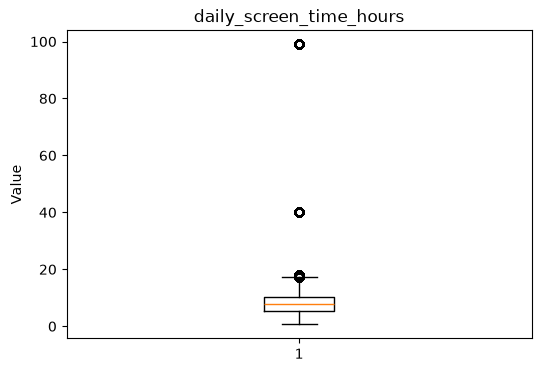

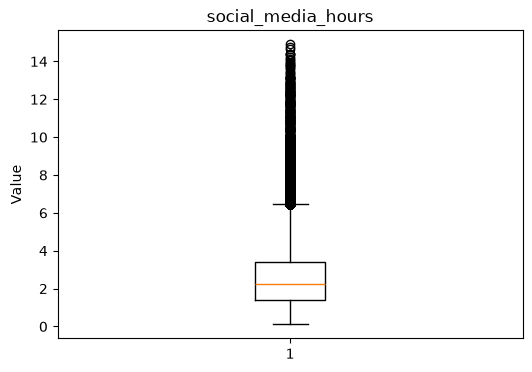

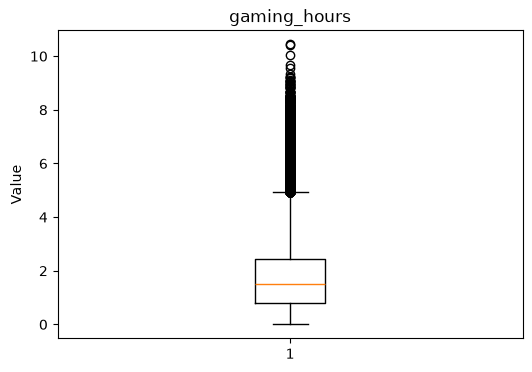

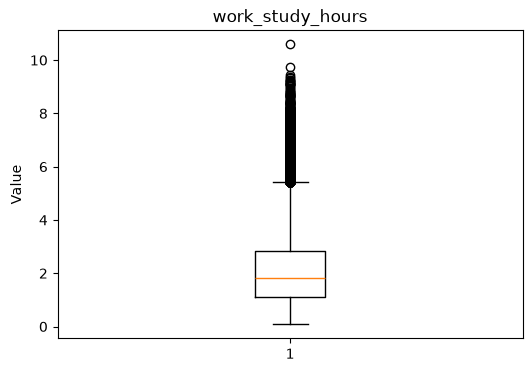

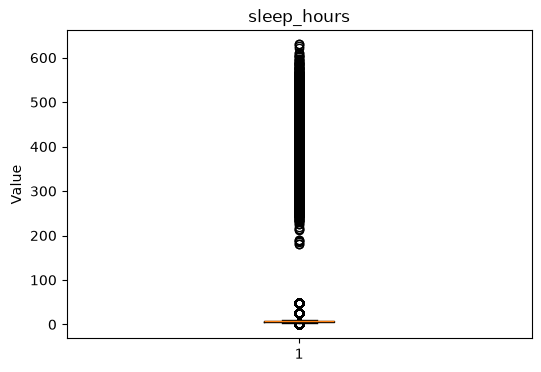

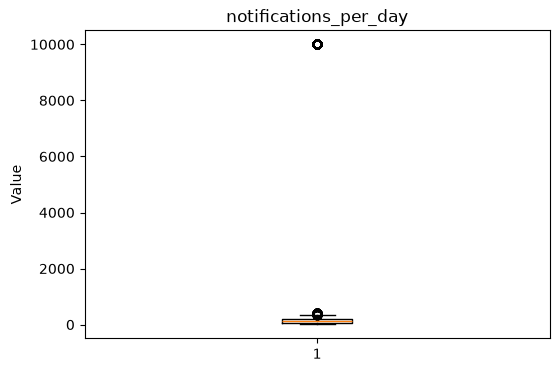

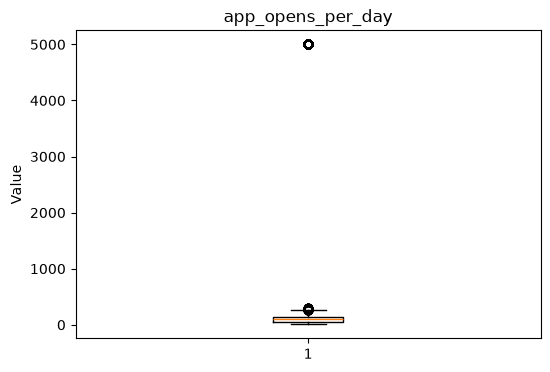

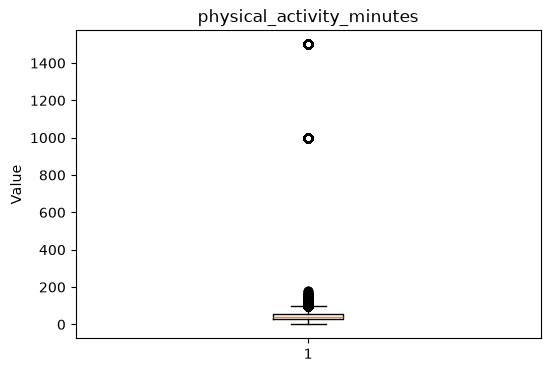

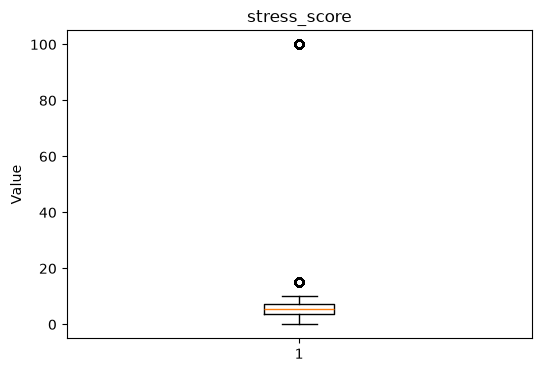

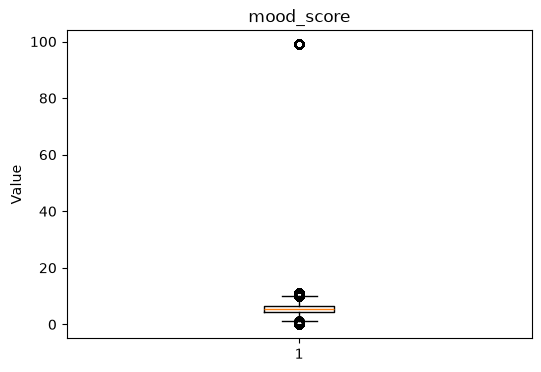

In [46]:
import matplotlib.pyplot as plt

for col in cols:
    plt.figure(figsize=(6, 4))
    plt.boxplot(df[col].dropna())
    plt.title(col)
    plt.ylabel("Value")
    plt.show()

In [47]:
print(df[cols].agg(["min", "max"]).T)

                            min      max
daily_screen_time_hours    0.66    99.00
social_media_hours         0.11    14.90
gaming_hours               0.00    10.44
work_study_hours           0.08    10.59
sleep_hours                0.00   630.00
notifications_per_day      8.00  9999.00
app_opens_per_day          7.00  5000.00
physical_activity_minutes  0.00  1500.00
stress_score               0.00   100.00
mood_score                 0.00    99.00


In [48]:
print("Screen time above 24:", (df["daily_screen_time_hours"] > 24).sum())
print("Sleep above 24:", (df["sleep_hours"] > 24).sum())
print("Social media above 24:", (df["social_media_hours"] > 24).sum())
print("Gaming above 24:", (df["gaming_hours"] > 24).sum())
print("Work/study above 24:", (df["work_study_hours"] > 24).sum())

Screen time above 24: 693
Sleep above 24: 2105
Social media above 24: 0
Gaming above 24: 0
Work/study above 24: 0


In [49]:
df.loc[df["daily_screen_time_hours"] > 24, "daily_screen_time_hours"] = float("nan")
df.loc[df["sleep_hours"] > 24, "sleep_hours"] = float("nan")

In [50]:
print("Screen time above 24:", (df["daily_screen_time_hours"] > 24).sum())
print("Sleep above 24:", (df["sleep_hours"] > 24).sum())

Screen time above 24: 0
Sleep above 24: 0


In [51]:
print("Notifications above 1000:", (df["notifications_per_day"] > 1000).sum())
print("App opens above 1000:", (df["app_opens_per_day"] > 1000).sum())

Notifications above 1000: 364
App opens above 1000: 542


In [52]:
print(df.loc[df["notifications_per_day"] > 1000, "notifications_per_day"].describe())
print(df.loc[df["app_opens_per_day"] > 1000, "app_opens_per_day"].describe())

count     364.0
mean     9999.0
std         0.0
min      9999.0
25%      9999.0
50%      9999.0
75%      9999.0
max      9999.0
Name: notifications_per_day, dtype: float64
count     542.0
mean     5000.0
std         0.0
min      5000.0
25%      5000.0
50%      5000.0
75%      5000.0
max      5000.0
Name: app_opens_per_day, dtype: float64


In [53]:
df.loc[df["notifications_per_day"] == 9999, "notifications_per_day"] = float("nan")

df.loc[df["app_opens_per_day"] == 5000, "app_opens_per_day"] = float("nan")

In [54]:
print("Notifications equal to 9999:",
      (df["notifications_per_day"] == 9999).sum())

print("App opens equal to 5000:",
      (df["app_opens_per_day"] == 5000).sum())

Notifications equal to 9999: 0
App opens equal to 5000: 0


In [55]:
print("Physical activity above 1440 minutes:",
      (df["physical_activity_minutes"] > 1440).sum())

print("Physical activity above 600 minutes:",
      (df["physical_activity_minutes"] > 600).sum())
      

Physical activity above 1440 minutes: 340
Physical activity above 600 minutes: 708


In [56]:
df.loc[df["physical_activity_minutes"] > 1440, "physical_activity_minutes"] = float("nan")

In [57]:
print("Physical activity above 1440 minutes:",
      (df["physical_activity_minutes"] > 1440).sum())

Physical activity above 1440 minutes: 0


In [58]:
print("Stress score below 0:", (df["stress_score"] < 0).sum())
print("Stress score above 100:", (df["stress_score"] > 100).sum())

print("Mood score below 0:", (df["mood_score"] < 0).sum())
print("Mood score above 100:", (df["mood_score"] > 100).sum())

Stress score below 0: 0
Stress score above 100: 0
Mood score below 0: 0
Mood score above 100: 0


In [59]:
print(df.isnull().sum()[df.isnull().sum() > 0])


daily_screen_time_hours      5749
social_media_hours           3136
gaming_hours                 3136
work_study_hours             3136
sleep_hours                  7060
notifications_per_day        4181
app_opens_per_day            4181
physical_activity_minutes    3813
stress_score                 3399
mood_score                   3397
stress_level                 3136
dtype: int64


In [60]:
for col in cols:
    df[col] = df[col].fillna(df[col].median())

In [61]:
df["stress_level"] = df["stress_level"].fillna(df["stress_level"].mode()[0])

In [62]:
print(df.isnull().sum()[df.isnull().sum() > 0])

Series([], dtype: int64)


In [63]:
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

Dataset shape: (261390, 19)
Duplicate rows: 0
Total missing values: 0


In [64]:
df.info()
df.head()

<class 'pandas.DataFrame'>
Index: 261390 entries, 0 to 265310
Data columns (total 19 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   record_id                  261390 non-null  str    
 1   user_id                    261390 non-null  str    
 2   date                       261390 non-null  str    
 3   day_index                  261390 non-null  str    
 4   day_of_week                261390 non-null  str    
 5   is_weekend                 261390 non-null  str    
 6   daily_screen_time_hours    261390 non-null  float64
 7   social_media_hours         261390 non-null  float64
 8   gaming_hours               261390 non-null  float64
 9   work_study_hours           261390 non-null  float64
 10  sleep_hours                261390 non-null  float64
 11  notifications_per_day      261390 non-null  float64
 12  app_opens_per_day          261390 non-null  float64
 13  physical_activity_minutes  261390 non-null  f

,record_id,user_id,date,day_index,day_of_week,is_weekend,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,physical_activity_minutes,stress_score,mood_score,is_anomaly,anomaly_type,stress_level
0,R0184779,U06160,2026-09-09,9,Wednesday,0,3.91,0.88,0.32,0.97,5.41,34.0,34.0,60.0,1.9,6.4,0,none,Low
1,R0128025,U04268,2026-09-15,15,Tuesday,0,10.73,1.56,2.87,5.78,5.12,121.0,98.0,39.0,6.7,5.3,0,none,Medium
2,R0146291,U04877,2026-11-09,11,Monday,0,7.68,4.56,1.71,1.05,6.78,18.0,128.0,49.0,5.6,4.4,0,none,Medium
3,R0213779,U07126,2026-09-29,29,Tuesday,0,10.27,1.20,0.22,0.87,3.65,43.0,27.0,46.0,10.0,2.6,1,late_night_usage,High
4,R0108909,U03631,2026-09-09,9,Wednesday,0,9.82,4.07,0.05,2.99,7.17,154.0,165.0,45.0,6.6,4.6,0,none,Medium


In [65]:
print("Stress score range:")
print(df["stress_score"].min(), df["stress_score"].max())

print("Mood score range:")
print(df["mood_score"].min(), df["mood_score"].max())

Stress score range:
0.0 100.0
Mood score range:
0.0 99.0


In [66]:
print("Rows and columns:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("Day of week matches date:",
      (pd.to_datetime(df["date"]).dt.day_name() == df["day_of_week"]).all())

Rows and columns: (261390, 19)
Missing values: 0
Duplicate rows: 0
Day of week matches date: True


In [67]:
df.to_csv("digital_wellbeing_cleaned.csv", index=False)

In [68]:
import os
print(os.path.abspath("digital_wellbeing_cleaned.csv"))

c:\Users\Admin\Documents\GitHub\Personalized-Digital-Wellbeing-System\notebooks\digital_wellbeing_cleaned.csv
